# Multi-Scale All-CNN Hybrid Extractor for Diabetic Retinopathy Grading

This notebook contains the complete PyTorch implementation of the **Multi-Scale All-CNN Hybrid Extractor** architecture designed for 5-class Diabetic Retinopathy (DR) grading using a Unilateral (single-eye) approach.

### Key Architecture Components:
1. **Global Context Branch**: Pre-trained `ResNet50` + `CBAM` Attention $\rightarrow F_{\text{global}} \in \mathbb{R}^{2048}$
2. **Local Patch Branch**: Pre-trained `EfficientNet-B0` + Reshape Trick + Patch Max-Pooling $\rightarrow F_{\text{local}} \in \mathbb{R}^{1280}$
3. **Intra-Fusion & MLP**: Feature concatenation ($3328$-dim) $\rightarrow$ 2-layer MLP $\rightarrow 512$-dim embedding

## 1. Import Essential Library

In [109]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import numpy as np
from PIL import Image
from typing import List, Tuple, Union, Dict, Optional, Any
from torch.utils.data import DataLoader
import sys
from pathlib import Path
import os
import albumentations as A
import cv2
import pandas as pd
from torch.utils.data import Dataset

# Thêm thư mục full chứa preprocessing.py vào hệ thống đường dẫn python
current_dir = Path().cwd()
full_pipeline_path = current_dir.parent.parent.parent / "pipeline" / "full"

if str(full_pipeline_path) not in sys.path:
    sys.path.append(str(full_pipeline_path))
# Sau đó import bình thường
from sklearn.metrics import cohen_kappa_score, confusion_matrix, accuracy_score, recall_score
import logging
# Setup module logger
logger = logging.getLogger("DRTrainer")
if not logger.handlers:
    handler = logging.StreamHandler()
    formatter = logging.Formatter("[%(levelname)s | %(asctime)s | DRTrainer] %(message)s")
    handler.setFormatter(formatter)
    logger.addHandler(handler)
logger.setLevel(logging.INFO)
import time
import matplotlib.pyplot as plt

## 2. Preprocessing & Load Dataset

### 2.1 Preprocessing Image Function

In [110]:
def apply_green_channel_ablation(
    img_rgb: np.ndarray, ablation_mode: str = "ben_graham_green"
) -> np.ndarray:
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    denoised = cv2.bilateralFilter(bgr, d=9, sigmaColor=75, sigmaSpace=75)
    b, g, r = cv2.split(denoised)

    if ablation_mode == "ben_graham_green":
        blurred = cv2.GaussianBlur(g, (0, 0), 30)
        adjusted = cv2.addWeighted(g, 4, blurred, -4, 128)
        processed = cv2.merge([adjusted, adjusted, adjusted])
    elif ablation_mode == "clahe_green":
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced_g = clahe.apply(g)
        processed = cv2.merge([enhanced_g, enhanced_g, enhanced_g])
    else:
        processed = cv2.merge([g, g, g])

    return cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)


### 2.2 Data augmentation for global branch

In [111]:
def get_global_augmentations(img_size: int = 300, is_train: bool = True):
    """
    Pipeline tăng cường dữ liệu và chuẩn hóa kích thước cho nhánh Global Context.
    """
    if is_train:
        return A.Compose([
            # 1. Sử dụng cv2.INTER_LINEAR thay vì INTER_BILINEAR
            A.Resize(height=img_size, width=img_size, interpolation=cv2.INTER_LINEAR),
            
            # 2. Các phép tăng cường không gian & màu sắc trên ảnh 300x300
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.05,
                scale_limit=0.1,
                rotate_limit=30,
                p=0.5,
                border_mode=cv2.BORDER_CONSTANT
            ),
            A.RandomBrightnessContrast(
                brightness_limit=0.1,
                contrast_limit=0.1,
                p=0.5
            ),
        ])
    else:
        return A.Compose([
            A.Resize(height=img_size, width=img_size, interpolation=cv2.INTER_LINEAR)
        ])

### 2.3 CLASS DATASET DUAL-BRANCH (Global Resize + Local Native)

In [112]:
class FundusDualBranchDataset(Dataset):
    def __init__(
        self,
        csv_path: str,
        img_size: int = 300,
        split: str = "train",
        ablation_mode: str = "ben_graham_green",
    ):
        """
        Dataset phục vụ cho mô hình đề xuất Dual-Branch (Global + Local MIL)
        hoặc chạy các mô hình Baseline đơn lẻ.
        """
        self.df = pd.read_csv(csv_path)
        self.img_size = img_size
        self.split = split
        self.ablation_mode = ablation_mode

        # Augmentation & Resize CHỈ áp dụng cho luồng Global / Baseline
        self.global_transform = get_global_augmentations(
            img_size, is_train=(split == "train")
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        native_path = row["native_path"]
        label = int(row["diagnosis"])

        # 1. Đọc ảnh gốc độ phân giải cao từ native path
        try:
            pil_img = Image.open(native_path).convert("RGB")
            img_np = np.array(pil_img)
        except Exception:
            img_np = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)

        # 2. Áp dụng tiền xử lý kênh Green
        processed_np = apply_green_channel_ablation(
            img_np, ablation_mode=self.ablation_mode
        )

        # ==========================================
        # LUỒNG 1: NHÁNH GLOBAL (HOẶC BASELINE) -> ĐÃ RESIZE CỐ ĐỊNH
        # ==========================================
        global_augmented = self.global_transform(image=processed_np)
        global_img = global_augmented["image"]

        # Chuyển tensor và chuẩn hóa Z-score cho Global
        global_tensor = (
            torch.tensor(global_img, dtype=torch.float32).permute(2, 0, 1)
            / 255.0
        )
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        global_tensor = (global_tensor - mean) / std

        # ==========================================
        # LUỒNG 2: NHÁNH LOCAL MIL -> GIỮ NGUYÊN NATIVE RESOLUTION
        # ==========================================
        # `processed_np` ở đây vẫn giữ nguyên kích thước lớn ban đầu của ảnh (ví dụ 2000x3000px).
        # Nhánh Local sẽ nhận mảng này để tiến hành cắt patch (hoặc bạn có thể convert thành tensor native).
        local_native_np = processed_np

        return {
            "global_image": global_tensor,  # Đã resize về [3, img_size, img_size] cho nhánh Global / Baseline
            "local_native_image": local_native_np,  # Giữ nguyên kích thước gốc để nhánh Local MIL cắt patch
            "native_path": native_path,  # Đường dẫn gốc
            "label": torch.tensor(label, dtype=torch.long),
        }

### 2.4 Cut patch for local mil branch

In [113]:
def extract_mil_patches(img_np: np.ndarray, patch_size: int = 128, num_patches: int = 16) -> torch.Tensor:
    """
    Cắt K patches (ví dụ 16 patches kích thước 128x128) từ ảnh gốc native resolution đã qua tiền xử lý kênh Green.
    Chuyển đổi sang PyTorch Tensor [K, 3, H, W] chuẩn hóa Z-score ImageNet.
    """
    h, w, _ = img_np.shape
    patches = []
    
    # Chiến lược chia lưới đều hoặc lấy ngẫu nhiên K vị trí chứa nhiều thông tin mạch máu
    # Đơn giản và chuẩn xác: chia lưới không gian (Grid-based extraction)
    grid_size = int(np.ceil(np.sqrt(num_patches)))
    step_h = max(1, (h - patch_size) // max(1, grid_size - 1)) if h > patch_size else 1
    step_w = max(1, (w - patch_size) // max(1, grid_size - 1)) if w > patch_size else 1
    
    for i in range(grid_size):
        for j in range(grid_size):
            if len(patches) >= num_patches:
                break
            start_h = min(i * step_h, h - patch_size)
            start_w = min(j * step_w, w - patch_size)
            
            # Cắt patch
            patch = img_np[start_h:start_h+patch_size, start_w:start_w+patch_size]
            
            # Padding nếu ảnh quá nhỏ
            if patch.shape[0] < patch_size or patch.shape[1] < patch_size:
                pad_h = max(0, patch_size - patch.shape[0])
                pad_w = max(0, patch_size - patch.shape[1])
                patch = np.pad(patch, ((0, pad_h), (0, pad_w), (0, 0)), mode='constant')
                
            patches.append(patch)
            
    # Đảm bảo đủ K patches (nếu thiếu lặp lại patch cuối)
    while len(patches) < num_patches:
        if len(patches) > 0:
            patches.append(patches[-1].copy())
        else:
            patches.append(np.zeros((patch_size, patch_size, 3), dtype=np.uint8))
        
    patches = patches[:num_patches]
    
    # Stack thành numpy array shape [K, H, W, 3] sau đó chuyển sang Tensor [K, 3, H, W]
    patches_np = np.stack(patches, axis=0)
    patches_tensor = torch.tensor(patches_np, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    
    # Chuẩn hóa Z-score theo ImageNet
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    patches_tensor = (patches_tensor - mean) / std
    
    return patches_tensor # Shape: [K=16, 3, 128, 128]


# ==========================================
# 2. CUSTOM COLLATE_FN ĐỒNG BỘ VỚI DRTRAINER
# ==========================================
def trainer_compatible_collate_fn(batch):
    """
    Gộp batch và map đúng tên key chuẩn cho DRTrainer:
    'global_img', 'local_patches', 'label'
    """
    # 1. Gom Global Images -> [B, 3, 300, 300]
    global_imgs = torch.stack([item["global_image"] for item in batch], dim=0)
    
    # 2. Cắt K patches cho từng ảnh native -> [B, 16, 3, 128, 128]
    local_patches_list = [
        extract_mil_patches(item["local_native_image"], patch_size=128, num_patches=16)
        for item in batch
    ]
    local_patches = torch.stack(local_patches_list, dim=0)
    
    # 3. Gom nhãn -> [B]
    labels = torch.stack([item["label"] for item in batch], dim=0)
    
    return {
        "global_img": global_imgs,
        "local_patches": local_patches,
        "label": labels
    }

## 2.5 Load Dataset

In [114]:
csv_train_path = "../../../../data/raw/samples/hybrid/native_cropped/sample_50_metadata.csv"
# Khởi tạo Dataset cho tập train (áp dụng augmentation và resize cho Global, giữ nguyên Native cho Local)
train_dataset = FundusDualBranchDataset(
    csv_path=csv_train_path,
    img_size=300,            # Kích thước cho nhánh Global / Baseline
    split="train",           # Bật augmentation cho tập train
    ablation_mode="ben_graham_green" # Chọn luồng tiền xử lý kênh Green
)
val_dataset = FundusDualBranchDataset(
    csv_path=csv_train_path, 
    img_size=300, 
    split="val", 
    ablation_mode="ben_graham_green"
)
# Khởi tạo DataLoader kèm theo custom_collate_fn
train_loader = DataLoader(
    train_dataset,
    batch_size=4,              # Chọn batch size phù hợp với GPU (ví dụ 8 hoặc 16 do ảnh local khá lớn)
    shuffle=True,
    num_workers=0,
    collate_fn=trainer_compatible_collate_fn # BẮT BUỘC CÓ ĐỂ XỬ LÝ ẢNH LOCAL NATIVE KHÁC KÍCH THƯỚC
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=4, 
    shuffle=False, 
    num_workers=0, 
    collate_fn=trainer_compatible_collate_fn
)

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### 2.6 Sample Image

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127757 (\N{EARTH GLOBE EUROPE-AFRICA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


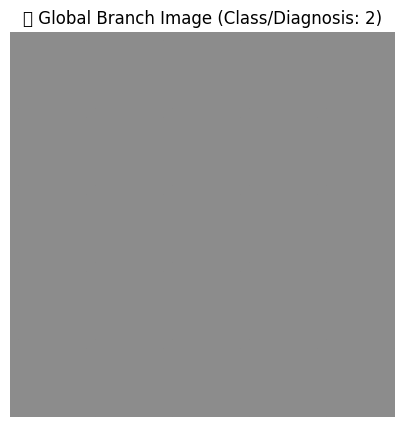

/tmp/ipykernel_69865/339691201.py:44: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


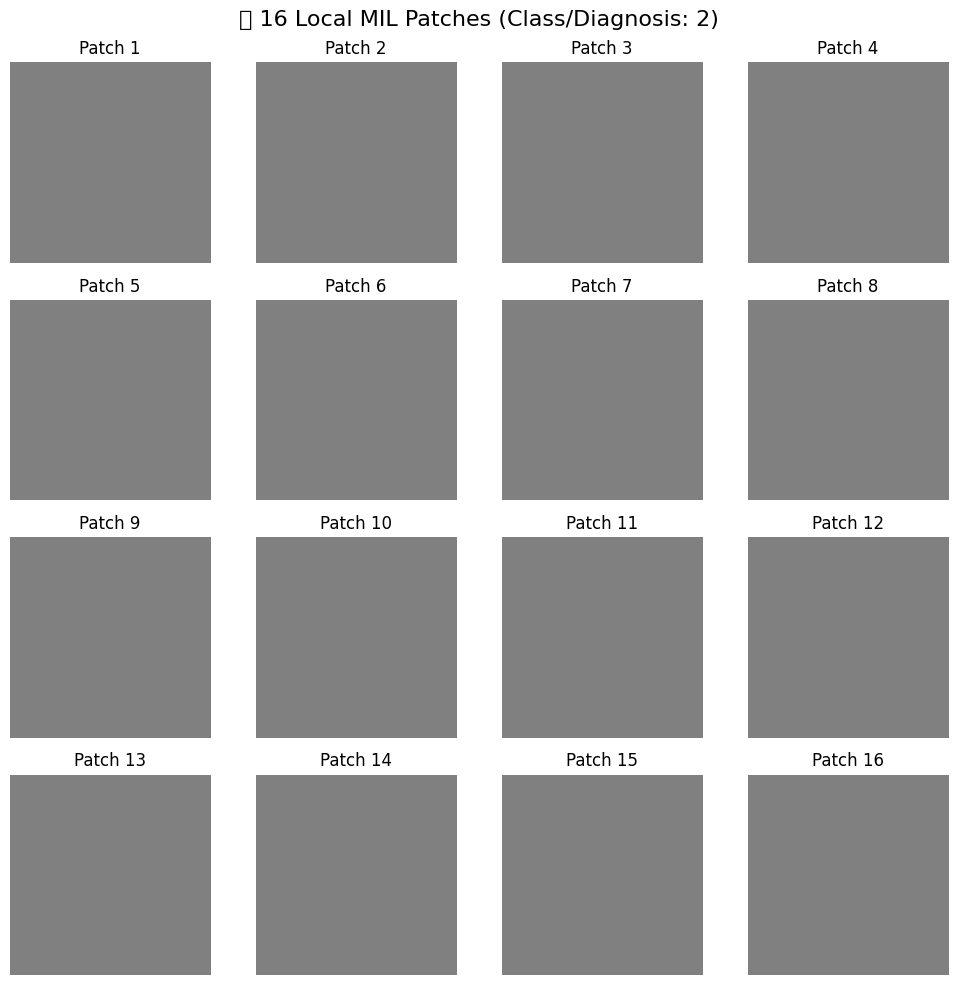

In [115]:
# 1. Lấy 1 batch từ train_loader
for batch in train_loader:
    global_imgs = batch["global_img"]    # Tensor: [4, 3, 300, 300]
    local_patches = batch["local_patches"] # Tensor: [4, 16, 3, 128, 128]
    labels = batch["label"]                # Tensor: [4]
    break

# Thông số chuẩn hóa ImageNet để đảo ngược (Denormalize) khi hiển thị ảnh
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# Chọn ảnh đầu tiên trong batch (index = 0) để kiểm chứng
img_idx = 0
label_val = labels[img_idx].item()

# ---------------------------------------------------------
# 2. HIỂN THỊ ẢNH GLOBAL (NHÁNH TOÀN CẢNH)
# ---------------------------------------------------------
global_img = global_imgs[img_idx].cpu() * std + mean  # Đảo ngược chuẩn hóa
global_img = torch.clamp(global_img, 0, 1).permute(1, 2, 0).numpy() # Đổi về [H, W, C]

plt.figure(figsize=(5, 5))
plt.imshow(global_img)
plt.title(f"🌍 Global Branch Image (Class/Diagnosis: {label_val})")
plt.axis("off")
plt.show()

# ---------------------------------------------------------
# 3. HIỂN THỊ CÁC PATCH LOCAL (NHÁNH MIL - 16 PATCHES)
# ---------------------------------------------------------
patches = local_patches[img_idx] # Tensor: [16, 3, 128, 128]

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle(f"🔍 16 Local MIL Patches (Class/Diagnosis: {label_val})", fontsize=16)

for i, ax in enumerate(axes.flatten()):
    patch = patches[i].cpu() * std + mean
    patch = torch.clamp(patch, 0, 1).permute(1, 2, 0).numpy()
    
    ax.imshow(patch)
    ax.title.set_text(f"Patch {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Build Model

### 3.1. Convolutional Block Attention Module (CBAM)

CBAM sequentially applies **Channel Attention** (combining Average Pooling and Max Pooling through a shared MLP) and **Spatial Attention** ($7\times7$ convolution over spatial channel projections).

In [116]:
class ChannelAttention(nn.Module):
    """
    Channel Attention Module for CBAM.
    Aggregates spatial information using AvgPool & MaxPool, feeding through a shared MLP.
    """
    def __init__(self, in_channels: int, reduction_ratio: int = 16):
        super(ChannelAttention, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        
        hidden_dim = max(8, in_channels // reduction_ratio)
        self.mlp = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden_dim, in_channels, kernel_size=1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        avg_out = self.mlp(self.avg_pool(x))
        max_out = self.mlp(self.max_pool(x))
        out = avg_out + max_out
        return self.sigmoid(out)

In [117]:
class SpatialAttention(nn.Module):
    """
    Spatial Attention Module for CBAM.
    Aggregates channel information via AvgPool & MaxPool along the channel axis,
    followed by a large 7x7 spatial convolution.
    """
    def __init__(self, kernel_size: int = 7):
        super(SpatialAttention, self).__init__()
        padding = (kernel_size - 1) // 2
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        combined = torch.cat([avg_out, max_out], dim=1)
        out = self.conv(combined)
        return self.sigmoid(out)

In [118]:
class CBAM(nn.Module):
    """
    Convolutional Block Attention Module (CBAM) sequentially applying
    Channel Attention and Spatial Attention.
    """
    def __init__(self, in_channels: int, reduction_ratio: int = 16, kernel_size: int = 7):
        super(CBAM, self).__init__()
        self.channel_att = ChannelAttention(in_channels, reduction_ratio=reduction_ratio)
        self.spatial_att = SpatialAttention(kernel_size=kernel_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Channel-refined feature map
        x_channel = x * self.channel_att(x)
        # Spatial-refined feature map
        x_out = x_channel * self.spatial_att(x_channel)
        return x_out

### 3.2. Global Context Branch (Zoom-out)

Processes whole-fundus images `[Batch, 3, 300, 300]` through pre-trained `ResNet50` feature extractor + `CBAM` attention $\rightarrow F_{\text{global}} \in \mathbb{R}^{\text{Batch} \times 2048}$.

In [119]:
class GlobalBranch(nn.Module):
    """
    Global Context Branch:
      Input: (B, 3, 300, 300)
      Backbone: ResNet-50 (Pretrained on ImageNet)
      Attention: CBAM applied to final conv layer feature map (2048 channels)
      Pooling: Global Average Pooling (GAP)
      Output: F_Global vector of dimension 2048
    """
    def __init__(self, pretrained: bool = True, use_cbam: bool = True):
        super(GlobalBranch, self).__init__()
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        base_resnet = models.resnet50(weights=weights)
        
        # Stem and ResNet layers 1 to 4
        self.conv1 = base_resnet.conv1
        self.bn1 = base_resnet.bn1
        self.relu = base_resnet.relu
        self.maxpool = base_resnet.maxpool
        self.layer1 = base_resnet.layer1
        self.layer2 = base_resnet.layer2
        self.layer3 = base_resnet.layer3
        self.layer4 = base_resnet.layer4  # Output: (B, 2048, H/32, W/32)
        
        self.use_cbam = use_cbam
        if use_cbam:
            self.cbam = CBAM(in_channels=2048, reduction_ratio=16)
            
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.out_dim = 2048

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, 3, 300, 300)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)  # (B, 2048, H', W')
        
        if self.use_cbam:
            x = self.cbam(x)
            
        feat = self.gap(x)  # (B, 2048, 1, 1)
        feat = torch.flatten(feat, 1)  # (B, 2048)
        return feat

### 3.3. LOCAL MIL BRANCH (EFFICIENTNET-B0 + 1D MAX-POOLING)

In [120]:
class LocalMILBranch(nn.Module):
    """
    Local Multi-Instance Learning (MIL) Branch:
      Input: (B, K=16, 3, 128, 128)
      Backbone: EfficientNet-B0 (Pretrained on ImageNet) applied per patch
      Pooling: GAP per patch -> (B, K, 1280)
      Aggregation: 1D Max-Pooling across the K=16 patch dimension -> F_Local (1280)
    """
    def __init__(self, pretrained: bool = True):
        super(LocalMILBranch, self).__init__()
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        base_effnet = models.efficientnet_b0(weights=weights)
        
        # Feature extractor layers
        self.features = base_effnet.features  # Output: (N, 1280, H', W')
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.out_dim = 1280

    def forward(self, patches: torch.Tensor) -> torch.Tensor:
        """
        Args:
            patches: Tensor of shape (B, K, 3, H_p, W_p)
            
        Returns:
            torch.Tensor: F_Local feature vector of shape (B, 1280)
        """
        B, K, C, H, W = patches.shape
        # Flatten batch and patch dimensions for parallel GPU feature extraction
        flat_patches = patches.view(B * K, C, H, W)  # (B*K, 3, 128, 128)
        
        patch_feats = self.features(flat_patches)    # (B*K, 1280, H', W')
        patch_feats = self.gap(patch_feats)          # (B*K, 1280, 1, 1)
        patch_feats = torch.flatten(patch_feats, 1)  # (B*K, 1280)
        
        # Reshape back to (B, K, 1280)
        patch_feats = patch_feats.view(B, K, self.out_dim)
        
        # Multi-Instance Max-Pooling across K patches: Selects salient lesion signatures
        # (e.g. maximum hemorrhage or microaneurysm confidence across any patch)
        f_local, _ = torch.max(patch_feats, dim=1)  # (B, 1280)
        return f_local


### 3.4. MULTI-SCALE DUAL-BRANCH FUSED ARCHITECTURE

In [121]:
class DualBranchMILModel(nn.Module):
    """
    Unified Dual-Branch Multi-Scale Deep Learning Network:
      Combines Global Context (ResNet-50 + CBAM) and Local Micro-Lesions (MIL EfficientNet-B0).
      Outputs a compact, fused latent embedding D_latent = 512 and final 5-class DR classification logits.
    """
    def __init__(
        self,
        pretrained: bool = True,
        use_cbam: bool = True,
        fusion_dim: int = 512,
        num_classes: int = 5,  # Số lượng lớp DR (0, 1, 2, 3, 4)
        dropout_rate: float = 0.3
    ):
        super(DualBranchMILModel, self).__init__()
        
        self.global_branch = GlobalBranch(pretrained=pretrained, use_cbam=use_cbam)
        self.local_mil_branch = LocalMILBranch(pretrained=pretrained)
        
        combined_dim = self.global_branch.out_dim + self.local_mil_branch.out_dim  # 2048 + 1280 = 3328[cite: 2]
        
        # Fusion projection module
        self.fusion_layer = nn.Sequential(
            nn.Linear(combined_dim, fusion_dim),
            nn.BatchNorm1d(fusion_dim),
            nn.Mish(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(fusion_dim, fusion_dim),
            nn.LayerNorm(fusion_dim)
        )
        self.latent_dim = fusion_dim

        # Thêm Classification Head đầu ra 5 mức độ DR
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, global_img: torch.Tensor, local_patches: torch.Tensor) -> Union[torch.Tensor, Tuple[torch.Tensor, torch.Tensor]]:
        """
        Args:
            global_img: (B, 3, 300, 300) global full fundus image[cite: 2].
            local_patches: (B, K=16, 3, 128, 128) high-res local patches[cite: 2].
            
        Returns:
            logits: (B, num_classes=5) điểm số dự đoán cho 5 mức độ DR (dùng cho CrossEntropyLoss).
            (Hoặc bạn có thể lấy thêm latent nếu cần trích xuất đặc trưng).
        """
        f_global = self.global_branch(global_img)      # (B, 2048)
        f_local = self.local_mil_branch(local_patches)   # (B, 1280)
        
        # Multimodal feature concatenation
        f_fused = torch.cat([f_global, f_local], dim=1)  # (B, 3328)
    
        # Latent projection (B, 512)
        latent = self.fusion_layer(f_fused)
    
        # QUAN TRỌNG: Trả về latent vector để DRFullModel đưa vào self.head!
        return latent

### 3.5 Build Model with other Classifier

#### 3.5.1 CONTINUOUS DIFFERENTIABLE QUADRATIC WEIGHTED KAPPA (QWK) LOSS

In [122]:
class ContinuousQWKLoss(nn.Module):
    """
    Differentiable approximation of Quadratic Weighted Kappa (QWK) Loss for PyTorch.
    Computes soft confusion matrix and soft quadratic penalty weighting:
      Loss = sum(W * O) / sum(W * E)
    """
    def __init__(self, num_classes: int = 5, eps: float = 1e-7):
        super(ContinuousQWKLoss, self).__init__()
        self.num_classes = num_classes
        self.eps = eps
        
        # Quadratic weight matrix W_ij = (i - j)^2 / (C - 1)^2
        w = torch.zeros((num_classes, num_classes), dtype=torch.float32)
        for i in range(num_classes):
            for j in range(num_classes):
                w[i, j] = ((i - j) ** 2) / ((num_classes - 1) ** 2)
        self.register_buffer("W", w)

    def forward(self, pred_probs: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        """
        Args:
            pred_probs: Softmax or cumulative probability distribution (B, num_classes).
            targets: Ground truth integer class labels (B,) or one-hot targets (B, num_classes).
        """
        device = pred_probs.device
        N = pred_probs.size(0)
        if N == 0:
            return torch.tensor(0.0, device=device, requires_grad=True)
            
        if targets.ndim == 1:
            y_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()
        else:
            y_one_hot = targets.float()
            
        # Ensure probabilities sum to 1
        pred_probs = pred_probs / (pred_probs.sum(dim=1, keepdim=True) + self.eps)
        
        # Soft observed confusion matrix: O = P^T * Y
        O = torch.matmul(pred_probs.t(), y_one_hot)  # (C, C)
        O = O / (N + self.eps)
        
        # Expected confusion matrix under independence: E = hist_pred * hist_true^T
        hist_pred = pred_probs.sum(dim=0, keepdim=True) / (N + self.eps)  # (1, C)
        hist_true = y_one_hot.sum(dim=0, keepdim=True) / (N + self.eps)   # (1, C)
        E = torch.matmul(hist_pred.t(), hist_true)                        # (C, C)
        
        # Quadratic weighted numerator and denominator
        W = self.W.to(device)
        num = torch.sum(W * O)
        den = torch.sum(W * E) + self.eps
        
        # QWK Loss = num / den (Minimizing this maximizes Cohen's Kappa)
        qwk_loss = num / den
        return qwk_loss

#### 3.5.2 OUTPUT HEAD 1: SOFTMAX CLASSIFICATION (CE)

In [123]:
class SoftmaxCEHead(nn.Module):
    """
    Standard Categorical Classification Head:
      Linear(latent_dim, 5) -> Cross-Entropy Loss.
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(SoftmaxCEHead, self).__init__()
        self.fc = nn.Linear(in_features, num_classes)
        self.num_classes = num_classes

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        logits = self.fc(x)  # (B, 5)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
        return {"logits": logits, "probs": probs, "preds": preds}

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        logits = outputs["logits"]
        return F.cross_entropy(logits, targets, weight=class_weights)

#### 3.5.3  OUTPUT HEAD 2: SOFTMAX + CONTINUOUS QWK LOSS

In [124]:
class SoftmaxQWKHead(nn.Module):
    """
    Softmax Classification Head trained with Hybrid Multitask Loss:
      Loss = Cross-Entropy + lambda * Continuous_QWK_Loss
    """
    def __init__(
        self,
        in_features: int = 512,
        num_classes: int = 5,
        qwk_weight: float = 1.0
    ):
        super(SoftmaxQWKHead, self).__init__()
        self.fc = nn.Linear(in_features, num_classes)
        self.num_classes = num_classes
        self.qwk_weight = qwk_weight
        self.qwk_loss = ContinuousQWKLoss(num_classes=num_classes)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        logits = self.fc(x)
        probs = F.softmax(logits, dim=1)
        # Expected continuous value for ordinal predictions
        continuous_pred = torch.sum(probs * torch.arange(self.num_classes, device=x.device), dim=1)
        preds = torch.round(continuous_pred).clamp(0, self.num_classes - 1).long()
        return {"logits": logits, "probs": probs, "preds": preds, "continuous_preds": continuous_pred}

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        logits = outputs["logits"]
        probs = outputs["probs"]
        
        ce_loss = F.cross_entropy(logits, targets, weight=class_weights)
        qwk = self.qwk_loss(probs, targets)
        
        total_loss = ce_loss + self.qwk_weight * qwk
        return total_loss


#### 3.5.4 OUTPUT HEAD 3: CORAL (CONSISTENT RANK LOGITS)

In [125]:
class CORALHead(nn.Module):
    """
    Consistent Rank Logits (CORAL) for Ordinal Regression.
    Features:
      - Shared weight vector W across all rank thresholds.
      - Independent rank threshold biases b_1, b_2, ..., b_{K-1}.
      - Probability of exceeding rank k: P(y > k) = sigmoid(W^T x + b_k).
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(CORALHead, self).__init__()
        self.num_classes = num_classes
        self.num_thresholds = num_classes - 1  # 4 thresholds for 5 classes
        
        # Shared linear weight (without bias)
        self.linear = nn.Linear(in_features, 1, bias=False)
        # Independent threshold biases
        self.biases = nn.Parameter(torch.zeros(self.num_thresholds))
        # Initialize biases to strictly increasing values
        with torch.no_grad():
            self.biases.copy_(torch.linspace(-2.0, 2.0, self.num_thresholds))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        base_logit = self.linear(x)  # (B, 1)
        # Binary rank logits for each threshold: z_k = W^T x + b_k
        rank_logits = base_logit + self.biases  # (B, 4)
        rank_probs = torch.sigmoid(rank_logits)  # P(y > k), shape (B, 4)
        
        # Predict class by counting number of satisfied thresholds (threshold > 0.5 -> logit > 0)
        preds = torch.sum(rank_probs > 0.5, dim=1).long()  # [0..4]
        
        # Reconstruct class probabilities: P(y = k) = P(y > k-1) - P(y > k)
        B = x.size(0)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = 1.0 - rank_probs[:, 0]
        for k in range(1, self.num_thresholds):
            probs[:, k] = F.relu(rank_probs[:, k - 1] - rank_probs[:, k])
        probs[:, -1] = rank_probs[:, -1]
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)
        
        return {"rank_logits": rank_logits, "rank_probs": rank_probs, "probs": probs, "preds": preds}

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        rank_logits = outputs["rank_logits"]  # (B, 4)
        device = targets.device
        B = targets.size(0)
        
        # Encode targets into binary rank indicators: binary_targets[i, k] = 1 if target > k else 0
        binary_targets = torch.zeros(B, self.num_thresholds, device=device)
        for k in range(self.num_thresholds):
            binary_targets[:, k] = (targets > k).float()
            
        # Standard Ordinal Binary Cross-Entropy across all rank thresholds
        bce_loss = F.binary_cross_entropy_with_logits(rank_logits, binary_targets, reduction="mean")
        return bce_loss

#### 3.5.5 OUTPUT HEAD 4: CORN (CONDITIONAL ORDINAL REGRESSION NN)

In [126]:
class CORNHead(nn.Module):
    """
    Conditional Ordinal Regression Neural Network (CORN).
    Models conditional probabilities: P(y > k | y >= k) = sigmoid(g(x)_k).
    Guarantees consistent probability chains without threshold crossing violations.
    """
    def __init__(self, in_features: int = 512, num_classes: int = 5):
        super(CORNHead, self).__init__()
        self.num_classes = num_classes
        self.num_thresholds = num_classes - 1  # 4 conditional tasks
        self.fc = nn.Linear(in_features, self.num_thresholds)

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        cond_logits = self.fc(x)  # (B, 4)
        cond_probs = torch.sigmoid(cond_logits)  # P(y > k | y >= k)
        
        # Compute cumulative probabilities: P(y > k) = prod_{j=0}^k P(y > j | y >= j)
        cum_probs = torch.cumprod(cond_probs, dim=1)  # (B, 4)
        
        # Predict class via thresholding cumulative probabilities
        preds = torch.sum(cum_probs > 0.5, dim=1).long()  # [0..4]
        
        # Reconstruct interval class probabilities
        B = x.size(0)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = 1.0 - cum_probs[:, 0]
        for k in range(1, self.num_thresholds):
            probs[:, k] = F.relu(cum_probs[:, k - 1] - cum_probs[:, k])
        probs[:, -1] = cum_probs[:, -1]
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)
        
        return {
            "cond_logits": cond_logits,
            "cond_probs": cond_probs,
            "cum_probs": cum_probs,
            "probs": probs,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        cond_logits = outputs["cond_logits"]  # (B, 4)
        B = targets.size(0)
        device = targets.device
        
        loss = 0.0
        valid_tasks = 0
        
        for k in range(self.num_thresholds):
            # Conditional subset: only samples where y >= k contribute to training the k-th head
            mask = (targets >= k)
            if mask.sum() > 0:
                subset_logits = cond_logits[mask, k]
                subset_targets = (targets[mask] > k).float()
                task_loss = F.binary_cross_entropy_with_logits(subset_logits, subset_targets)
                loss += task_loss
                valid_tasks += 1
                
        return loss / max(1, valid_tasks)

#### 3.5.6 OUTPUT HEAD 5: CLM_QWK (CHAMPION - CUMULATIVE LINK MODEL + QWK)

In [127]:
class CumulativeLinkModelQWKHead(nn.Module):
    """
    Champion Output Architecture: Cumulative Link Model (CLM) with Complementary Log-Log (clog-log)
    Link Function & Hybrid Continuous QWK Loss.
    
    Mathematical Formulation:
      - Latent Severity Score: s(x) = W^T x (scalar continuous representation)
      - Strictly Monotonic Cutpoints: theta_1 < theta_2 < theta_3 < theta_4
      - Complementary Log-Log (clog-log) link: F(z) = 1 - exp(-exp(z))
      - Cumulative Probability: P(Y <= k) = 1 - exp(-exp(theta_k - s(x)))
      - Interval Probability: P(Y = k) = P(Y <= k) - P(Y <= k-1)
      - Loss: Negative Log-Likelihood (NLL) + lambda * Continuous_QWK_Loss
    """
    def __init__(
        self,
        in_features: int = 512,
        num_classes: int = 5,
        qwk_weight: float = 1.2
    ):
        super(CumulativeLinkModelQWKHead, self).__init__()
        self.num_classes = num_classes
        self.num_cutpoints = num_classes - 1  # 4 cutpoints for 5 grades
        self.qwk_weight = qwk_weight
        
        # Linear projection to single latent severity score
        self.score_fc = nn.Linear(in_features, 1, bias=False)
        
        # Parameterize monotonic cutpoints using exponential increments:
        # theta_1 = c_1, theta_k = theta_{k-1} + exp(delta_k)
        self.first_cutpoint = nn.Parameter(torch.tensor(-1.5))
        self.cutpoint_increments = nn.Parameter(torch.ones(self.num_cutpoints - 1) * -0.5)
        
        self.qwk_loss = ContinuousQWKLoss(num_classes=num_classes)

    def _get_monotonic_cutpoints(self) -> torch.Tensor:
        """Computes strictly ordered cutpoints theta_1 < theta_2 < ... < theta_4."""
        increments = F.softplus(self.cutpoint_increments) + 1e-4  # Strictly positive
        cutpoints = [self.first_cutpoint]
        for i in range(len(increments)):
            cutpoints.append(cutpoints[-1] + increments[i])
        return torch.stack(cutpoints)  # (4,)

    def _cloglog_cdf(self, z: torch.Tensor) -> torch.Tensor:
        """Complementary log-log link function: F(z) = 1 - exp(-exp(z))."""
        # Clamp to avoid numerical overflow in double exponential
        z_clamped = torch.clamp(z, min=-10.0, max=4.0)
        return 1.0 - torch.exp(-torch.exp(z_clamped))

    def forward(self, x: torch.Tensor) -> Dict[str, torch.Tensor]:
        B = x.size(0)
        severity_score = self.score_fc(x).squeeze(1)  # (B,)
        cutpoints = self._get_monotonic_cutpoints()    # (4,)
        
        # Compute latent differences: (theta_k - s(x)) of shape (B, 4)
        z = cutpoints.unsqueeze(0) - severity_score.unsqueeze(1)
        
        # Cumulative probabilities P(Y <= k) for k = 0, 1, 2, 3
        cum_probs = self._cloglog_cdf(z)  # (B, 4)
        
        # Compute discrete interval probabilities P(Y = k)
        probs = torch.zeros(B, self.num_classes, device=x.device)
        probs[:, 0] = cum_probs[:, 0]
        for k in range(1, self.num_cutpoints):
            probs[:, k] = F.relu(cum_probs[:, k] - cum_probs[:, k - 1])
        probs[:, -1] = F.relu(1.0 - cum_probs[:, -1])
        
        # Normalize to valid probability simplex
        probs = probs / (probs.sum(dim=1, keepdim=True) + 1e-7)
        
        # Expected continuous grade prediction
        class_indices = torch.arange(self.num_classes, device=x.device, dtype=torch.float32)
        expected_grade = torch.sum(probs * class_indices, dim=1)  # (B,)
        preds = torch.round(expected_grade).clamp(0, self.num_classes - 1).long()
        
        return {
            "severity_score": severity_score,
            "cutpoints": cutpoints,
            "cum_probs": cum_probs,
            "probs": probs,
            "expected_grade": expected_grade,
            "preds": preds
        }

    def loss_fn(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        probs = outputs["probs"]  # (B, 5)
        B = targets.size(0)
        
        # 1. Negative Log-Likelihood of observed ordinal grade intervals
        eps = 1e-7
        target_probs = probs[torch.arange(B, device=targets.device), targets]
        nll_loss = -torch.log(torch.clamp(target_probs, min=eps))
        
        if class_weights is not None:
            weights_per_sample = class_weights[targets]
            nll_loss = (nll_loss * weights_per_sample).mean()
        else:
            nll_loss = nll_loss.mean()
            
        # 2. Continuous Quadratic Weighted Kappa Loss
        qwk = self.qwk_loss(probs, targets)
        
        total_loss = nll_loss + self.qwk_weight * qwk
        return total_loss


In [128]:
class DRFullModel(nn.Module):
    """
    End-to-End Deep Learning Architecture integrating DualBranchMILModel backbone
    with any of the 5 selectable Ordinal Regression Heads.
    """
    def __init__(
        self,
        backbone: nn.Module,
        head_type: str = "CLM_QWK",
        num_classes: int = 5,
        qwk_weight: float = 1.2
    ):
        super(DRFullModel, self).__init__()
        self.backbone = backbone
        self.head_type = head_type
        self.num_classes = num_classes
        latent_dim = getattr(backbone, "latent_dim", 512)
        
        # Instantiate requested head
        head_key = head_type.upper()
        if head_key in ["SOFTMAX_CE", "CE"]:
            self.head = SoftmaxCEHead(in_features=latent_dim, num_classes=num_classes)
        elif head_key in ["SOFTMAX_QWK", "QWK"]:
            self.head = SoftmaxQWKHead(in_features=latent_dim, num_classes=num_classes, qwk_weight=qwk_weight)
        elif head_key in ["CORAL"]:
            self.head = CORALHead(in_features=latent_dim, num_classes=num_classes)
        elif head_key in ["CORN"]:
            self.head = CORNHead(in_features=latent_dim, num_classes=num_classes)
        elif head_key in ["CLM_QWK", "CLM", "CHAMPION"]:
            self.head = CumulativeLinkModelQWKHead(in_features=latent_dim, num_classes=num_classes, qwk_weight=qwk_weight)
        else:
            raise ValueError(f"Unknown head_type: '{head_type}'. Choose from Softmax_CE, Softmax_QWK, CORAL, CORN, CLM_QWK.")

    def forward(self, global_img: torch.Tensor, local_patches: torch.Tensor) -> Dict[str, torch.Tensor]:
        latent = self.backbone(global_img, local_patches)
        outputs = self.head(latent)
        outputs["latent"] = latent
        return outputs

    def compute_loss(
        self,
        outputs: Dict[str, torch.Tensor],
        targets: torch.Tensor,
        class_weights: Optional[torch.Tensor] = None
    ) -> torch.Tensor:
        return self.head.loss_fn(outputs, targets, class_weights=class_weights)

#### 3.5.7 Build model 

In [129]:
def build_model(
    head_type: str = "CLM_QWK",
    pretrained: bool = True,
    use_cbam: bool = True,
    fusion_dim: int = 512,
    num_classes: int = 5,
    qwk_weight: float = 1.2
) -> DRFullModel:
    """
    Factory function to construct complete DR Multi-Scale Pipeline model with designated output head.
    
    Args:
        head_type: 'Softmax_CE', 'Softmax_QWK', 'CORAL', 'CORN', or 'CLM_QWK'.
        pretrained: Whether backbones use ImageNet pretrained weights.
        use_cbam: Whether to enable CBAM attention on ResNet-50.
        fusion_dim: Dimension of latent multimodal embedding.
        num_classes: 5 ordinal severity grades (0 to 4).
        qwk_weight: Weight coefficient for continuous QWK loss term.
        
    Returns:
        DRFullModel: Assembled PyTorch neural network.
    """
        
    backbone = DualBranchMILModel(
        pretrained=pretrained,
        use_cbam=use_cbam,
        fusion_dim=fusion_dim
    )
    
    model = DRFullModel(
        backbone=backbone,
        head_type=head_type,
        num_classes=num_classes,
        qwk_weight=qwk_weight
    )
    return model

In [130]:
model = build_model(
    head_type="CLM_QWK",
    pretrained=True,
    use_cbam=True,
    fusion_dim=512,
    num_classes=5,
    qwk_weight=1.2
)

### 3.6 Set up Optimizer & Learning Rate Scheduler

In [131]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10, eta_min=1e-6)

## 4. Training Model

### 4.1 COMPREHENSIVE MEDICAL & ORDINAL METRICS CALCULATOR

In [132]:
def calculate_dr_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    num_classes: int = 5
) -> Dict[str, Any]:
    """
    Computes rigorous clinical and statistical evaluation metrics for 5-grade DR classification.
    
    Args:
        y_true: Array of ground truth integer labels [0..4].
        y_pred: Array of predicted integer labels [0..4].
        num_classes: Number of ordinal severity classes (5).
        
    Returns:
        Dict[str, Any]: Comprehensive metrics dictionary.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    
    # 1. Quadratic Weighted Kappa (QWK)
    qwk = float(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
    if np.isnan(qwk):
        qwk = 0.0
        
    # 2. Accuracy
    acc = float(accuracy_score(y_true, y_pred))
    
    # 3. Within-1-Grade Accuracy: Tolerance metric for clinical viability
    within_1 = float(np.mean(np.abs(y_true - y_pred) <= 1))
    
    # 4. Confusion Matrix & Per-grade Recalls
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    per_grade_recall = {}
    for c in range(num_classes):
        denom = cm[c, :].sum()
        recall = float(cm[c, c] / denom) if denom > 0 else 0.0
        per_grade_recall[f"Recall_Grade_{c}"] = recall
        
    # 5. Referable DR Metrics (Non-referable: 0,1 vs Referable: 2,3,4)
    # Standard gold-standard ophthalmology referral threshold
    y_true_ref = (y_true >= 2).astype(int)
    y_pred_ref = (y_pred >= 2).astype(int)
    
    cm_ref = confusion_matrix(y_true_ref, y_pred_ref, labels=[0, 1])
    tn, fp, fn, tp = cm_ref.ravel() if cm_ref.size == 4 else (0, 0, 0, 0)
    
    ref_sensitivity = float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0
    ref_specificity = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0
    
    return {
        "QWK": qwk,
        "Accuracy": acc,
        "Within_1_Grade_Acc": within_1,
        "Referable_Sensitivity": ref_sensitivity,
        "Referable_Specificity": ref_specificity,
        "Confusion_Matrix": cm.tolist(),
        **per_grade_recall
    }

In [133]:
def calculate_monotonicity_violations(probs: np.ndarray) -> float:
    """
    Measures the frequency of rank monotonicity violations in cumulative ordinal probability outputs.
    Cumulative probabilities must satisfy: P(Y <= 0) <= P(Y <= 1) <= ... <= P(Y <= 4).
    
    Args:
        probs: Array of discrete class probabilities (N, 5).
        
    Returns:
        float: Fraction of samples exhibiting inverted probability order.
    """
    cum_probs = np.cumsum(probs, axis=1)
    diffs = np.diff(cum_probs, axis=1)
    # A violation occurs if any consecutive difference is negative (numerical tolerance 1e-4)
    violations = np.any(diffs < -1e-4, axis=1)
    return float(np.mean(violations))

### 4.2 PYTORCH TRAINING & EVALUATION ENGINE

In [134]:
class DRTrainer:
    """
    High-Performance PyTorch Training & Evaluation Engine tích hợp sẵn cơ chế Callbacks:
      - ModelCheckpoint (Lưu mô hình tốt nhất dựa trên QWK).
      - ReduceLROnPlateau (Tự động hạ Learning Rate khi val_loss chững lại).
      - EarlyStopping (Dừng sớm khi val_loss không cải thiện để chống học vẹt/overfitting).
    """
    def __init__(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        lr_scheduler: Optional[Any] = None,
        device: str = "cuda" if torch.cuda.is_available() else "cpu",
        use_amp: bool = True,
        class_weights: Optional[torch.Tensor] = None,
        grad_clip: float = 1.0,
        checkpoint_dir: str = "./checkpoints"
    ):
        self.model = model.to(device)
        self.optimizer = optimizer
        self.lr_scheduler = lr_scheduler
        self.device = device
        # Xác định device_type ('cuda' hoặc 'cpu') cho torch.amp
        self.device_type = "cuda" if "cuda" in str(device) else "cpu"
        self.use_amp = use_amp and (self.device_type == "cuda")
        
        self.class_weights = class_weights.to(device) if class_weights is not None else None
        self.grad_clip = grad_clip
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        
        self.scaler = torch.cuda.amp.GradScaler(self.device_type,enabled=self.use_amp)

    def train_epoch(self, dataloader: DataLoader) -> Dict[str, float]:
        """Runs one full training epoch over the dataset."""
        self.model.train()
        total_loss = 0.0
        all_preds = []
        all_targets = []
        
        for batch in dataloader:
            global_img = batch["global_img"].to(self.device, non_blocking=True)
            local_patches = batch["local_patches"].to(self.device, non_blocking=True)
            targets = batch["label"].to(self.device, non_blocking=True)
            
            self.optimizer.zero_grad()
            
            # Forward pass with Automatic Mixed Precision
            with torch.cuda.amp.autocast(self.device_type, enabled=self.use_amp):
                outputs = self.model(global_img, local_patches)
                loss = self.model.compute_loss(outputs, targets, class_weights=self.class_weights)
                
            # Backward pass with scaled gradients
            self.scaler.scale(loss).backward()
            if self.grad_clip > 0:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
                
            self.scaler.step(self.optimizer)
            self.scaler.update()
            
            total_loss += loss.item() * len(targets)
            all_preds.extend(outputs["preds"].detach().cpu().numpy())
            all_targets.extend(targets.detach().cpu().numpy())
            
        # if self.lr_scheduler is not None:
        #     self.lr_scheduler.step()
            
        n_samples = len(all_targets)
        epoch_loss = total_loss / max(1, n_samples)
        metrics = calculate_dr_metrics(all_targets, all_preds)
        metrics["Loss"] = epoch_loss
        return metrics

    @torch.no_grad()
    def evaluate(self, dataloader: DataLoader) -> Tuple[Dict[str, Any], np.ndarray, np.ndarray]:
        """Evaluates the model on validation or out-of-domain test sets."""
        self.model.eval()
        total_loss = 0.0
        all_preds = []
        all_targets = []
        all_probs = []
        
        for batch in dataloader:
            global_img = batch["global_img"].to(self.device, non_blocking=True)
            local_patches = batch["local_patches"].to(self.device, non_blocking=True)
            targets = batch["label"].to(self.device, non_blocking=True)
            
            with torch.cuda.amp.autocast(self.device_type, enabled=self.use_amp):
                outputs = self.model(global_img, local_patches)
                loss = self.model.compute_loss(outputs, targets, class_weights=self.class_weights)
                
            total_loss += loss.item() * len(targets)
            all_preds.extend(outputs["preds"].cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
            if "probs" in outputs:
                all_probs.extend(outputs["probs"].cpu().numpy())
                
        n_samples = len(all_targets)
        eval_loss = total_loss / max(1, n_samples)
        metrics = calculate_dr_metrics(all_targets, all_preds)
        metrics["Loss"] = eval_loss
        
        if all_probs:
            probs_np = np.array(all_probs)
            metrics["Monotonicity_Violations"] = calculate_monotonicity_violations(probs_np)
            
        return metrics, np.array(all_targets), np.array(all_preds)

    def fit(
        self,
        train_loader: DataLoader,
        val_loader: DataLoader,
        test_loader: Optional[DataLoader] = None,
        epochs: int = 20,
        model_name: str = "dr_model",
        # --- CÁC THAM SỐ CALLBACKS TƯƠNG ĐƯƠNG KERAS ---
        patience_early_stopping: int = 12,  # EarlyStopping patience=12
        patience_reduce_lr: int = 4,        # ReduceLROnPlateau patience=4
        reduce_lr_factor: float = 0.5,      # ReduceLROnPlateau factor=0.5
        min_lr: float = 1e-6                # Ngưỡng LR tối thiểu
    ) -> Dict[str, Any]:
        """
        Executes full multi-epoch training loop with model checkpointing based on best validation QWK.
        """
        best_val_qwk = -1.0
        best_val_loss = float("inf")
        
        # Biến đếm phục vụ Callbacks
        epochs_no_improve_es = 0
        epochs_no_improve_lr = 0
        history: Dict[str, List[float]] = {
            "train_loss": [], "val_loss": [],
            "train_qwk": [], "val_qwk": [],
            "val_within_1": [], "val_ref_sens": []
        }
        
        best_checkpoint_path = os.path.join(self.checkpoint_dir, f"{model_name}_best.pth")
        
        logger.info(f"Beginning Training for {epochs} Epochs on Device: {self.device}")
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            train_metrics = self.train_epoch(train_loader)
            val_metrics, _, _ = self.evaluate(val_loader)
            elapsed = time.time() - t0
            # Nếu dùng CosineAnnealingLR truyền thống, có thể gọi step() ở đây hoặc để scheduler tự chạy
            if self.lr_scheduler is not None and not isinstance(self.lr_scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                self.lr_scheduler.step()
            
            val_loss = val_metrics["Loss"]
            val_qwk = val_metrics["QWK"]
            current_lr = self.optimizer.param_groups[0]['lr']
            
            history["train_loss"].append(train_metrics["Loss"])
            history["val_loss"].append(val_loss)
            history["train_qwk"].append(train_metrics["QWK"])
            history["val_qwk"].append(val_qwk)
            history["val_within_1"].append(val_metrics["Within_1_Grade_Acc"])
            history["val_ref_sens"].append(val_metrics["Referable_Sensitivity"])
            
            logger.info(
                f"[Epoch {epoch:02d}/{epochs:02d} - {elapsed:.1f}s] "
                f"Train Loss: {train_metrics['Loss']:.4f} | Train QWK: {train_metrics['QWK']:.4f} || "
                f"Val Loss: {val_loss:.4f} | Val QWK: {val_qwk:.4f} | "
                f"Val Within-1: {val_metrics['Within_1_Grade_Acc']*100:.1f}% | "
                f"Val Ref-Sens: {val_metrics['Referable_Sensitivity']*100:.1f}% |",
                f"LR: {current_lr:.2e}" 
            )
            
            # Save checkpoint on improved validation QWK
            if val_qwk > best_val_qwk:
                best_val_qwk = val_qwk
                torch.save({
                    "epoch": epoch,
                    "model_state_dict": self.model.state_dict(),
                    "optimizer_state_dict": self.optimizer.state_dict(),
                    "val_qwk": best_val_qwk,
                    "val_metrics": val_metrics
                }, best_checkpoint_path)
                logger.info(f"  -> Saved new best model checkpoint to '{best_checkpoint_path}' (Val QWK: {best_val_qwk:.4f})")
            
            # ------------------------------------------------------------------
            # 2. REDUCE LR ON PLATEAU (Hạ LR nếu val_loss chững lại)
            # ------------------------------------------------------------------
            if val_loss < best_val_loss - 1e-4:  # Cải thiện đáng kể
                best_val_loss = val_loss
                epochs_no_improve_lr = 0
                epochs_no_improve_es = 0  # Reset early stopping khi val_loss cải thiện
            else:
                epochs_no_improve_lr += 1
                epochs_no_improve_es += 1
                
                if epochs_no_improve_lr >= patience_reduce_lr:
                    old_lr = current_lr
                    new_lr = max(old_lr * reduce_lr_factor, min_lr)
                    if old_lr > min_lr:
                        for param_group in self.optimizer.param_groups:
                            param_group['lr'] = new_lr
                        logger.info(f"  -> [ReduceLROnPlateau] Val loss stagnant for {patience_reduce_lr} epochs. Reducing LR: {old_lr:.2e} -> {new_lr:.2e}")
                    epochs_no_improve_lr = 0

                # ------------------------------------------------------------------
                # 3. EARLY STOPPING (Dừng sớm chống học vẹt)
                # ------------------------------------------------------------------
                if epochs_no_improve_es >= patience_early_stopping:
                    logger.info(f"  -> [EarlyStopping] Validation loss unimproved for {patience_early_stopping} epochs. Stopping training early!")
                    break
        # Load best model for OOD Test evaluation if provided
        test_metrics = {}
        if test_loader is not None and os.path.exists(best_checkpoint_path):
            logger.info("Loading best model weights for Out-Of-Domain (OOD) Test evaluation...")
            ckpt = torch.load(best_checkpoint_path, map_location=self.device)
            self.model.load_state_dict(ckpt["model_state_dict"])
            test_metrics, _, _ = self.evaluate(test_loader)
            
            delta_qwk = best_val_qwk - test_metrics["QWK"]
            test_metrics["Delta_QWK"] = delta_qwk
            
            logger.info(
                f"=== OOD TEST RESULTS ===\n"
                f"OOD Test QWK: {test_metrics['QWK']:.4f} | "
                f"In-Domain Val QWK: {best_val_qwk:.4f} | "
                f"Delta_QWK (Domain Shift Drop): {delta_qwk:.4f} | "
                f"OOD Within-1: {test_metrics['Within_1_Grade_Acc']*100:.1f}% | "
                f"OOD Ref-Sens: {test_metrics['Referable_Sensitivity']*100:.1f}%"
            )
            
        return {
            "best_val_qwk": best_val_qwk,
            "best_checkpoint": best_checkpoint_path,
            "history": history,
            "ood_test_metrics": test_metrics
        }

In [135]:
trainer = DRTrainer(
    model=model,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    device="cuda" if torch.cuda.is_available() else "cpu",
    use_amp=True,
    grad_clip=1.0,
    checkpoint_dir="./checkpoints"
)

    # Bắt đầu chạy vòng lặp huấn luyện (Fit)
history = trainer.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,  # Có thể tăng lên 20-30 epochs khi chạy thật
    model_name="dual_branch_clm_qwk",
    patience_early_stopping=12, # Dừng sau 12 epoch không cải thiện loss
    patience_reduce_lr=4        # Giảm một nửa LR sau 4 epoch không cải thiện loss
)

print("\n🎉 Huấn luyện thành công toàn bộ Pipeline!")

/tmp/ipykernel_69865/54718520.py:32: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(self.device_type,enabled=self.use_amp)
[INFO | 2026-08-24 14:30:51,850 | DRTrainer] Beginning Training for 100 Epochs on Device: cuda
/tmp/ipykernel_69865/54718520.py:49: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self.device_type, enabled=self.use_amp):


TypeError: autocast.__init__() got multiple values for argument 'enabled'